# 3 · L'élasticité 2D : déformation, contrainte, élément Q1

*Notebook 3 du cours. Il suppose le [notebook 1](01_discretisation.ipynb) (grille, nœuds, numérotation) et le [notebook 2](02_fem_1d.ipynb) (assemblage, $\mathbf K\mathbf u=\mathbf f$, compliance).*

Au notebook 2, la barre ne pouvait que s'allonger. Une pièce 2D peut s'étirer dans deux directions, se **cisailler** et tourner. Pour la décrire, il faut trois notions qui remplacent « l'allongement relatif » et « la force par section » de la barre :

- la **déformation** $\boldsymbol\varepsilon$ (comment la matière se déforme),
- la **contrainte** $\boldsymbol\sigma$ (les efforts internes),
- la **loi de comportement** $\boldsymbol\sigma=\mathbf C\boldsymbol\varepsilon$ (le matériau).

Ensuite, on construit **la** matrice élémentaire $\mathbf K_e^0$ de l'élément à 4 nœuds (8 inconnues), on l'assemble sur toute une grille, et on **valide** le résultat sur un cas où la solution est connue (une poutre console). On termine avec un trou dans une pièce, pour voir *pourquoi retirer de la matière coûte plus ou moins cher selon l'endroit* : c'est le cœur de l'optimisation topologique.

**Plan.**
1. Déformation ; 2. Contrainte et loi de Hooke (dont le cas orthotrope des pièces imprimées) ;
3. L'élément Q1 et sa matrice $\mathbf K_e^0$, avec cinq vérifications ;
4. Assemblage 2D et appuis ; 5. Validation sur une console ; 6. L'effet d'un trou.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. La déformation : trois nombres

Une pièce se déplace de $\mathbf u(x,z)=(u_x,u_z)$ en chaque point. Mais un **déplacement d'ensemble ne déforme rien** : si on translate ou fait tourner la pièce, elle ne s'abîme pas. Ce qui compte pour la matière, c'est la **variation** du déplacement d'un point à son voisin, c'est-à-dire ses dérivées. Pour de petits déplacements on retient trois combinaisons :

$$
\varepsilon_{xx}=\frac{\partial u_x}{\partial x},\qquad
\varepsilon_{zz}=\frac{\partial u_z}{\partial z},\qquad
\gamma_{xz}=\frac{\partial u_x}{\partial z}+\frac{\partial u_z}{\partial x}.
$$

- $\varepsilon_{xx}$ : allongement relatif selon $x$ (comme la barre du notebook 2) ;
- $\varepsilon_{zz}$ : allongement relatif selon $z$ ;
- $\gamma_{xz}$ : **cisaillement**, la variation de l'angle droit entre deux côtés d'un petit carré (en radians). On utilise ici le cisaillement « d'ingénierie » $\gamma=2\varepsilon_{xz}$ ; c'est la convention du projet (vecteur $\boldsymbol\varepsilon=(\varepsilon_{xx},\varepsilon_{zz},\gamma_{xz})$, ordre de Voigt, [FORMALISM §0](../../FORMALISM.md)).

Voyons-le sur un petit carré, auquel on impose un déplacement dont le gradient est constant.

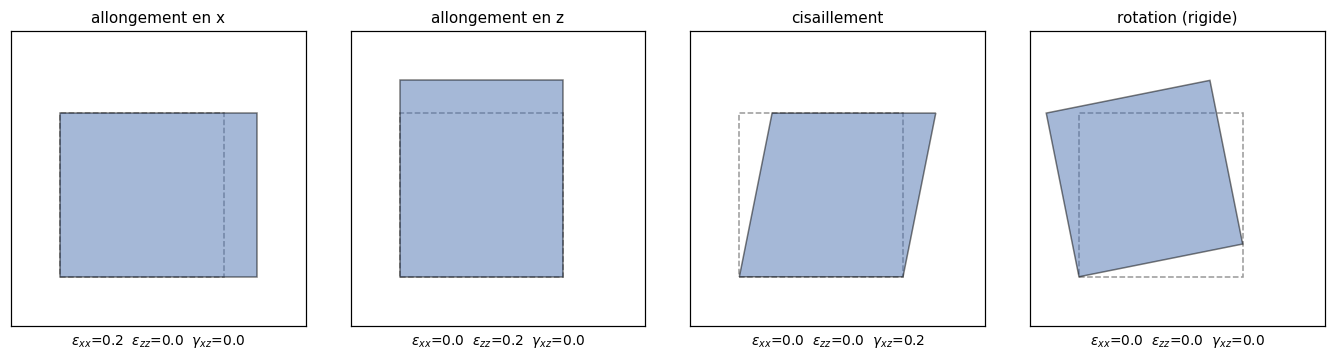

In [2]:
e = 0.2
cas = [
    ("allongement en x",   np.array([[e, 0.0], [0.0, 0.0]])),
    ("allongement en z",   np.array([[0.0, 0.0], [0.0, e]])),
    ("cisaillement",       np.array([[0.0, e], [0.0, 0.0]])),      # u_x = e z
    ("rotation (rigide)",  np.array([[0.0, -e], [e, 0.0]])),       # u = e (-z, x)
]
carre = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float)

fig, axs = plt.subplots(1, 4, figsize=(12.5, 3.1))
for ax, (nom, G) in zip(axs, cas):
    # G = gradient du déplacement : [[dux/dx, dux/dz], [duz/dx, duz/dz]]
    eps = np.array([G[0, 0], G[1, 1], G[0, 1] + G[1, 0]])
    ax.add_patch(Polygon(carre, fill=False, ec="0.6", ls="--"))
    ax.add_patch(Polygon(carre @ (np.eye(2) + G).T, fc="#4c72b0", alpha=0.5, ec="k"))
    ax.set_xlim(-0.3, 1.5); ax.set_ylim(-0.3, 1.5); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(nom, fontsize=10)
    ax.set_xlabel(f"$\\varepsilon_{{xx}}$={eps[0]:.1f}  $\\varepsilon_{{zz}}$={eps[1]:.1f}  $\\gamma_{{xz}}$={eps[2]:.1f}", fontsize=9)
plt.tight_layout(); plt.show()

(Les valeurs sont volontairement grandes pour être visibles ; la théorie suppose des déformations très petites, de l'ordre de $10^{-3}$.)

**Point crucial : la rotation d'ensemble donne $\varepsilon=\mathbf 0$** ($\partial_z u_x=-e$ et $\partial_x u_z=+e$ s'annulent dans $\gamma_{xz}$). C'est pourquoi la matrice de rigidité aura des modes sans énergie : deux translations et une rotation, soit **3 modes rigides en 2D** (6 en 3D).

## 2. La contrainte et la loi de Hooke

La **contrainte** est une force par unité de surface, exercée *à l'intérieur* de la matière entre deux parties voisines. Sur un petit carré, il y a trois composantes : deux contraintes **normales** $\sigma_{xx}$, $\sigma_{zz}$ (on tire ou on pousse sur une face) et une contrainte de **cisaillement** $\sigma_{xz}$ (on fait glisser une face le long de l'autre).

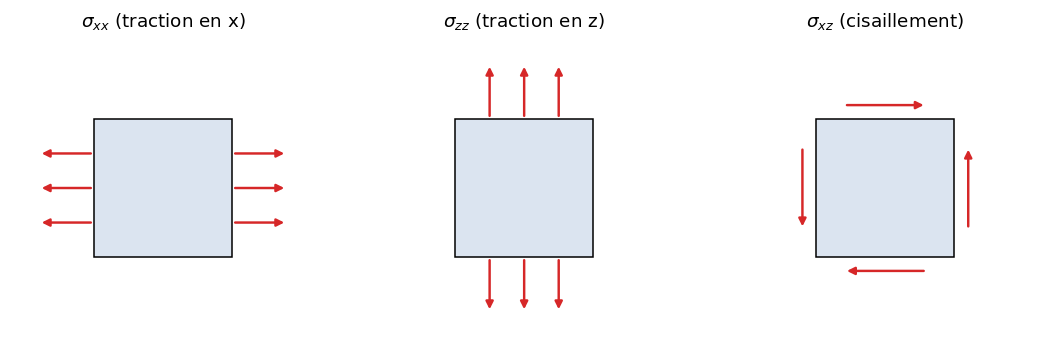

In [3]:
def fleche(ax, p0, p1):
    ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.6))

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, titre in zip(axs, [r"$\sigma_{xx}$ (traction en x)", r"$\sigma_{zz}$ (traction en z)", r"$\sigma_{xz}$ (cisaillement)"]):
    ax.add_patch(Rectangle((0, 0), 1, 1, fc="#dbe4f0", ec="k"))
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(-0.6, 1.6); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(titre)
for y in (0.25, 0.5, 0.75):
    fleche(axs[0], (1, y), (1.4, y)); fleche(axs[0], (0, y), (-0.4, y))
    fleche(axs[1], (y, 1), (y, 1.4)); fleche(axs[1], (y, 0), (y, -0.4))
fleche(axs[2], (1.1, 0.2), (1.1, 0.8)); fleche(axs[2], (-0.1, 0.8), (-0.1, 0.2))
fleche(axs[2], (0.2, 1.1), (0.8, 1.1)); fleche(axs[2], (0.8, -0.1), (0.2, -0.1))
plt.tight_layout(); plt.show()

### Loi de Hooke en 3D, puis réduction en 2D

Un matériau **élastique linéaire** relie les contraintes aux déformations par une matrice : $\boldsymbol\sigma=\mathbf C\,\boldsymbol\varepsilon$, ou à l'envers $\boldsymbol\varepsilon=\mathbf S\,\boldsymbol\sigma$ avec $\mathbf S=\mathbf C^{-1}$. La matrice $\mathbf S$ (la **souplesse**, ou *compliance matrix*) est plus lisible car chaque coefficient se mesure par un essai de traction :

- $S_{11}=1/E_1$ : on tire selon l'axe 1 avec $\sigma_1$, l'allongement vaut $\sigma_1/E_1$ ;
- $S_{12}=-\nu_{12}/E_1$ : on tire selon 1, la matière **se contracte** selon 2 de $\nu_{12}\sigma_1/E_1$ (effet Poisson) ;
- $S_{44}=1/G_{23}$ : le module de cisaillement $G$ relie cisaillement et contrainte de cisaillement.

Un matériau **orthotrope** (trois plans de symétrie, typiquement le bois, les composites… et **les pièces imprimées en FDM**) a 9 constantes indépendantes ; c'est la loi retenue par le projet ([FORMALISM §3.1](../../FORMALISM.md)). Les cas particuliers : l'isotrope ($E$, $\nu$, avec $G=E/2(1+\nu)$) et l'isotrope transverse d'axe $z$ (couches imprimées isotropes dans le plan $x,y$, plus faibles selon $z$).

Pour passer à la 2D (plan $x,z$ ; $y$ hors plan) il faut dire ce qui se passe selon $y$. Deux idéalisations :

- **Contraintes planes** (plaque mince : les faces libres imposent $\sigma_{yy}=0$) : on extrait de $\mathbf S$ les lignes/colonnes $\{xx,zz,xz\}$ **puis on inverse** ;
- **Déformations planes** (tranche d'un solide très long en $y$ : $\varepsilon_{yy}=0$) : on inverse $\mathbf S$ en 3D **puis on extrait** les mêmes lignes/colonnes.

Le projet utilise par défaut les contraintes planes (bras mince).

In [4]:
def S_orthotrope(E1, E2, E3, G23, G13, G12, nu12, nu13, nu23):
    # Matrice de souplesse 6x6, ordre de Voigt (xx, yy, zz, yz, xz, xy). FORMALISM §3.1.
    S = np.zeros((6, 6))
    S[0, 0], S[1, 1], S[2, 2] = 1 / E1, 1 / E2, 1 / E3
    S[0, 1] = S[1, 0] = -nu12 / E1
    S[0, 2] = S[2, 0] = -nu13 / E1
    S[1, 2] = S[2, 1] = -nu23 / E2
    S[3, 3], S[4, 4], S[5, 5] = 1 / G23, 1 / G13, 1 / G12
    np.linalg.cholesky(S)                       # lève une erreur si S n'est pas définie positive (matériau non admissible)
    return S

PLAN = [0, 2, 4]                                # indices de (xx, zz, xz) dans l'ordre de Voigt 3D

def C_contraintes_planes(S3):
    return np.linalg.inv(S3[np.ix_(PLAN, PLAN)])       # extraire PUIS inverser

def C_deformations_planes(S3):
    return np.linalg.inv(S3)[np.ix_(PLAN, PLAN)]       # inverser PUIS extraire

# --- Matériau isotrope : on retrouve les formules classiques ---
E, nu = 1.0, 0.3
G = E / (2 * (1 + nu))
S_iso = S_orthotrope(E, E, E, G, G, G, nu, nu, nu)

C_cp = C_contraintes_planes(S_iso)
C_dp = C_deformations_planes(S_iso)
classique_cp = E / (1 - nu ** 2) * np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu) / 2]])
classique_dp = E / ((1 + nu) * (1 - 2 * nu)) * np.array([[1 - nu, nu, 0], [nu, 1 - nu, 0], [0, 0, (1 - 2 * nu) / 2]])
print("contraintes planes  = formule classique :", np.allclose(C_cp, classique_cp))
print("déformations planes = formule classique :", np.allclose(C_dp, classique_dp))
print("\nC (contraintes planes), E = 1, nu = 0.3 :\n", C_cp)
print("\nC (déformations planes) :\n", C_dp)

contraintes planes  = formule classique : True
déformations planes = formule classique : True

C (contraintes planes), E = 1, nu = 0.3 :
 [[1.0989 0.3297 0.    ]
 [0.3297 1.0989 0.    ]
 [0.     0.     0.3846]]

C (déformations planes) :
 [[1.3462 0.5769 0.    ]
 [0.5769 1.3462 0.    ]
 [0.     0.     0.3846]]


Les deux idéalisations donnent des matrices **différentes** : en déformations planes le matériau est plus raide (on lui interdit de se dilater en $y$). Le choix est donc physique, pas anecdotique.

### Le cas du projet : l'orthotropie des couches imprimées

La loi est **la même** ; seule $\mathbf S$ change. Prenons les valeurs *provisoires* de la configuration du drone (à calibrer par essais, [FORMALISM §6](../../FORMALISM.md)) : $E_p=2{,}4$ GPa dans le plan des couches, $E_z=1{,}8$ GPa dans l'axe d'empilement, avec $z$ comme axe faible.

In [5]:
Ep, Ez, nup, nupz, Gz = 2.4e9, 1.8e9, 0.35, 0.35, 0.7e9       # valeurs PROVISOIRES (config drone_arm_2d)
Gp = Ep / (2 * (1 + nup))
S_ti = S_orthotrope(Ep, Ep, Ez, Gz, Gz, Gp, nup, nupz, nupz)    # isotrope transverse d'axe z
C_ti = C_contraintes_planes(S_ti)
print("C isotrope transverse, contraintes planes [GPa] :\n", C_ti / 1e9)

# Traction de 1 MPa selon x, puis selon z : la déformation n'est pas la même
S2 = S_ti[np.ix_(PLAN, PLAN)]
for nom, sig in [("selon x (dans les couches)", [1e6, 0, 0]), ("selon z (entre les couches)", [0, 1e6, 0])]:
    eps = S2 @ np.array(sig)
    print(f"traction 1 MPa {nom:28s}: eps_xx = {eps[0]:.3e}, eps_zz = {eps[1]:.3e}")

C isotrope transverse, contraintes planes [GPa] :
 [[2.6428 0.6937 0.    ]
 [0.6937 1.9821 0.    ]
 [0.     0.     0.7   ]]
traction 1 MPa selon x (dans les couches)  : eps_xx = 4.167e-04, eps_zz = -1.458e-04
traction 1 MPa selon z (entre les couches) : eps_xx = -1.458e-04, eps_zz = 5.556e-04


Pour la même contrainte, la déformation selon $z$ est $E_p/E_z=1{,}33$ fois plus grande : le matériau est moins rigide entre les couches. **Cette anisotropie ne change rien à l'algorithme** : il suffit de remplacer $\mathbf C_0$ par celle-ci, avant de construire la matrice élémentaire. (Attention : une raideur plus faible n'est pas une *résistance* plus faible ; la rupture inter-couches est un autre sujet, voir [FORMALISM §9, H3](../../FORMALISM.md).)

## 3. L'élément Q1 et sa matrice $\mathbf K_e^0$

L'élément rectangulaire à 4 nœuds du notebook 1 porte $4\times2=8$ déplacements nodaux $\mathbf u_e=(u_{x,0},u_{z,0},\dots,u_{x,3},u_{z,3})$. Le déplacement dans l'élément est interpolé par les fonctions de forme $N_a$ (notebook 1), donc la déformation en un point se calcule **linéairement** à partir de $\mathbf u_e$ :

$$\boldsymbol\varepsilon=\mathbf B\,\mathbf u_e,\qquad
\mathbf B=\big[\mathbf B_0\ \mathbf B_1\ \mathbf B_2\ \mathbf B_3\big],\qquad
\mathbf B_a=\begin{pmatrix}\partial_xN_a&0\\0&\partial_zN_a\\\partial_zN_a&\partial_xN_a\end{pmatrix}.$$

$\mathbf B$ (matrice **déformation–déplacement**) est la généralisation 2D du vecteur $(-1/h\ \ 1/h)$ du notebook 2. À la différence du 1D, $\mathbf B$ **dépend du point** $(\xi,\eta)$ : la déformation varie dans l'élément.

L'énergie de déformation de l'élément est $\tfrac12\int\boldsymbol\varepsilon^\top\mathbf C\boldsymbol\varepsilon\,dV=\tfrac12\,\mathbf u_e^\top\mathbf K_e^0\,\mathbf u_e$ avec

$$\mathbf K_e^0=t\int_{\text{élément}}\mathbf B^\top\mathbf C_0\,\mathbf B\;dx\,dz\;=\;t\sum_{g=1}^{4}w_g\,\det J\;\mathbf B_g^\top\mathbf C_0\,\mathbf B_g .$$

L'intégrale est calculée **exactement** par une quadrature de Gauss à $2\times2$ points $(\pm1/\sqrt3,\pm1/\sqrt3)$ (poids 1), car l'intégrande est un polynôme de degré $\le2$ par variable. Les dérivées physiques se déduisent de celles de l'élément de référence : $\partial_x=\tfrac{2}{h_x}\partial_\xi$, $\partial_z=\tfrac{2}{h_z}\partial_\eta$, et $\det J=h_xh_z/4$. Comme tous les éléments d'une grille uniforme sont identiques, **cette matrice $8\times8$ est calculée une seule fois**.

In [6]:
SIGNES = np.array([[-1, -1], [-1, +1], [+1, -1], [+1, +1]])     # coins : bas-gauche, haut-gauche, bas-droit, haut-droit (notebook 1)

def B_q1(xi, eta, hx, hz):
    # Matrice déformation-déplacement (3 x 8) au point (xi, eta) de l'élément de référence.
    dN_dxi = SIGNES[:, 0] * (1 + SIGNES[:, 1] * eta) / 4
    dN_deta = SIGNES[:, 1] * (1 + SIGNES[:, 0] * xi) / 4
    dN_dx, dN_dz = dN_dxi * 2 / hx, dN_deta * 2 / hz
    B = np.zeros((3, 8))
    B[0, 0::2] = dN_dx                 # eps_xx  = d(ux)/dx
    B[1, 1::2] = dN_dz                 # eps_zz  = d(uz)/dz
    B[2, 0::2] = dN_dz                 # gamma_xz = d(ux)/dz + d(uz)/dx
    B[2, 1::2] = dN_dx
    return B

def Ke0_q1(C, hx, hz, t=1.0):
    g = 1 / np.sqrt(3)
    Ke = np.zeros((8, 8))
    for xi in (-g, g):
        for eta in (-g, g):
            B = B_q1(xi, eta, hx, hz)
            Ke += t * (hx * hz / 4) * B.T @ C @ B     # poids de Gauss = 1
    return Ke

Ke = Ke0_q1(C_cp, 1.0, 1.0)                           # carré unité, E = 1, nu = 0.3, contraintes planes
print(Ke)

[[ 0.4945  0.1786  0.0549  0.0137 -0.3022 -0.0137 -0.2473 -0.1786]
 [ 0.1786  0.4945 -0.0137 -0.3022  0.0137  0.0549 -0.1786 -0.2473]
 [ 0.0549 -0.0137  0.4945 -0.1786 -0.2473  0.1786 -0.3022  0.0137]
 [ 0.0137 -0.3022 -0.1786  0.4945  0.1786 -0.2473 -0.0137  0.0549]
 [-0.3022  0.0137 -0.2473  0.1786  0.4945 -0.1786  0.0549 -0.0137]
 [-0.0137  0.0549  0.1786 -0.2473 -0.1786  0.4945  0.0137 -0.3022]
 [-0.2473 -0.1786 -0.3022 -0.0137  0.0549  0.0137  0.4945  0.1786]
 [-0.1786 -0.2473  0.0137  0.0549 -0.0137 -0.3022  0.1786  0.4945]]


### Cinq vérifications

Avoir une matrice $8\times8$ n'est pas la même chose que l'avoir **juste**. Voici cinq tests indépendants, dont deux ont une interprétation physique à retenir.

1. **Symétrie** : $\mathbf K_e^0=\mathbf K_e^{0\top}$ (réciprocité de Maxwell).
2. **Trois valeurs propres nulles, cinq strictement positives** : les 3 modes rigides du §1.
3. **Mouvement rigide ⇒ aucune force** : une translation ou une rotation de l'élément ne doit engendrer aucune force nodale.
4. **Patch test** : pour un champ de déformation uniforme, l'énergie calculée doit être *exactement* $\tfrac12\boldsymbol\varepsilon^\top\mathbf C\boldsymbol\varepsilon\times\text{volume}$ (un élément qui échoue ne peut pas représenter un état de déformation constant, donc ne convergera pas).
5. **Comparaison à une référence indépendante** : la matrice fermée du code classique *top88* (Andreassen et al., 2011), écrite pour un carré unité avec une autre numérotation des coins (anti-horaire, d'où une permutation).

In [7]:
hx, hz, t = 2.0, 1.0, 0.5                      # élément rectangulaire quelconque pour les tests 1 à 4
Ke_t = Ke0_q1(C_ti, hx, hz, t)                  # avec le matériau orthotrope du §2

# 1. symétrie
print("1. symétrique              :", np.allclose(Ke_t, Ke_t.T))

# 2. spectre
vp = np.linalg.eigvalsh(Ke_t / np.abs(Ke_t).max())
print("2. valeurs propres (norm.) :", vp, "\n   -> modes nuls :", int((np.abs(vp) < 1e-10).sum()), "; positives :", int((vp > 1e-10).sum()))

# coordonnées des 4 coins dans l'ordre local, et champs de déplacement nodaux
coins = np.array([[0, 0], [0, hz], [hx, 0], [hx, hz]])
def champ_nodal(ux, uz):
    return np.column_stack([ux(coins[:, 0], coins[:, 1]), uz(coins[:, 0], coins[:, 1])]).ravel()

# 3. mouvements rigides : translation en x, en z, rotation
th = 1e-3
rigides = {
    "translation x": champ_nodal(lambda x, z: 1 + 0 * x, lambda x, z: 0 * x),
    "translation z": champ_nodal(lambda x, z: 0 * x, lambda x, z: 1 + 0 * x),
    "rotation":      champ_nodal(lambda x, z: -th * z, lambda x, z: th * x),
}
ref = np.abs(Ke_t).max()
for nom, u in rigides.items():
    print(f"3. forces nodales ({nom:13s}) : max |Ke u| / max |Ke| = {np.abs(Ke_t @ u).max() / (ref * max(np.abs(u).max(), 1e-12)):.1e}")

# 4. patch test : déformation uniforme (exx, ezz, gamma)
eps = np.array([1e-3, -3e-4, 2e-4])
u = champ_nodal(lambda x, z: eps[0] * x + 0.5 * eps[2] * z, lambda x, z: eps[1] * z + 0.5 * eps[2] * x)
E_fem = 0.5 * u @ Ke_t @ u
E_exacte = 0.5 * eps @ C_ti @ eps * (hx * hz * t)
print(f"4. énergie FEM = {E_fem:.6e}   exacte = {E_exacte:.6e}   écart relatif = {abs(E_fem - E_exacte) / E_exacte:.1e}")

# 5. référence top88 (carré unité, E = 1, nu = 0.3, contraintes planes)
def KE_top88(nu):
    k = np.array([1/2 - nu/6, 1/8 + nu/8, -1/4 - nu/12, -1/8 + 3*nu/8, -1/4 + nu/12, -1/8 - nu/8, nu/6, 1/8 - 3*nu/8])
    idx = np.array([[0, 1, 2, 3, 4, 5, 6, 7], [1, 0, 7, 6, 5, 4, 3, 2], [2, 7, 0, 5, 6, 3, 4, 1], [3, 6, 5, 0, 7, 2, 1, 4],
                    [4, 5, 6, 7, 0, 1, 2, 3], [5, 4, 3, 2, 1, 0, 7, 6], [6, 3, 4, 1, 2, 7, 0, 5], [7, 2, 1, 4, 3, 6, 5, 0]])
    return k[idx] / (1 - nu ** 2)

noeuds_top88 = [0, 3, 1, 2]        # notre coin (bas-g, haut-g, bas-d, haut-d) -> son numéro dans l'ordre anti-horaire de top88
perm = np.array([2 * n + c for n in noeuds_top88 for c in (0, 1)])
print("5. écart max avec top88    :", np.abs(KE_top88(0.3)[np.ix_(perm, perm)] - Ke).max())

1. symétrique              : True
2. valeurs propres (norm.) : [-0.      0.      0.      0.6308  0.7999  1.      1.2169  2.8756] 
   -> modes nuls : 3 ; positives : 5
3. forces nodales (translation x) : max |Ke u| / max |Ke| = 4.1e-17
3. forces nodales (translation z) : max |Ke u| / max |Ke| = 3.1e-17
3. forces nodales (rotation     ) : max |Ke u| / max |Ke| = 4.0e-17
4. énergie FEM = 1.216478e+03   exacte = 1.216478e+03   écart relatif = 3.7e-16
5. écart max avec top88    : 1.6653345369377348e-16


Les cinq tests passent. Notez le rôle du test 5 : une référence **écrite par d'autres** et un écart à l'erreur machine. Dans le projet, ces vérifications sont des tests automatiques (`tests/unit`, contrats C-ELEM-xx) ; le notebook les montre en clair.

## 4. Assemblage 2D et appuis

On reprend la numérotation du notebook 1 (nœud $=i(n_z+1)+k$, ddl $=2\cdot\text{nœud}+c$) et l'assemblage du notebook 2 : **gather → matrice élémentaire → scatter-add**. À chaque élément on associe un facteur de rigidité $s_e$ (pour l'instant 1 ; plus tard la densité SIMP) : $\mathbf K=\sum_e s_e\,\mathbf A_e^\top\mathbf K_e^0\mathbf A_e$.

Comme $\mathbf K$ est maintenant grande et creuse, on la stocke au format **creux** (`scipy.sparse`). Le scatter-add est fait par la conversion COO → CSR, qui additionne automatiquement les doublons (équivalent du `np.add.at` du notebook 2).

K : 56 x 56, 760 coefficients non nuls (24 %)
valeurs propres de K sans appui : 3 nulles  (= 3 modes rigides)


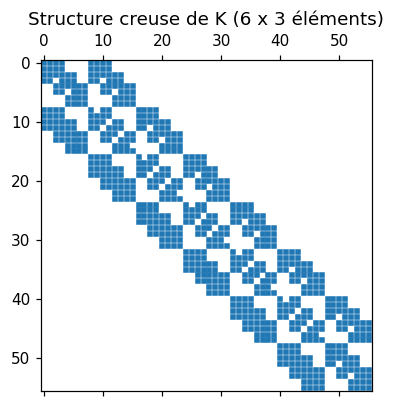

In [8]:
def connectivite_2d(nx, nz):
    i, k = np.meshgrid(np.arange(nx), np.arange(nz), indexing="ij")
    return (i * (nz + 1) + k).reshape(-1, 1) + np.array([0, 1, nz + 1, nz + 2])     # (Ne, 4)

def ddl_2d(conn):
    return (2 * conn[:, :, None] + np.arange(2)).reshape(len(conn), 8)               # (Ne, 8)

def assembler_K(s_e, Ke0, nx, nz):
    ed = ddl_2d(connectivite_2d(nx, nz))
    Ne, Nu = len(ed), 2 * (nx + 1) * (nz + 1)
    lignes = np.broadcast_to(ed[:, :, None], (Ne, 8, 8))
    colonnes = np.broadcast_to(ed[:, None, :], (Ne, 8, 8))
    valeurs = s_e[:, None, None] * Ke0[None, :, :]                                   # (Ne, 8, 8) : s_e * Ke0
    K = sp.coo_matrix((valeurs.ravel(), (lignes.ravel(), colonnes.ravel())), shape=(Nu, Nu)).tocsr()
    return K, ed

def resoudre(K, f, bloques):
    # K_tilde = P K P + (I - P), identité sur les ddl bloqués (FORMALISM §3.4).
    p = np.ones(K.shape[0]); p[bloques] = 0.0
    P = sp.diags(p)
    Kt = (P @ K @ P + sp.diags(1 - p)).tocsc()
    return spla.spsolve(Kt, P @ f)

# --- petit exemple : structure de K sur 6 x 3 éléments ---
nx_p, nz_p = 6, 3
Kp, _ = assembler_K(np.ones(nx_p * nz_p), Ke, nx_p, nz_p)
vp = np.linalg.eigvalsh(Kp.toarray())
print(f"K : {Kp.shape[0]} x {Kp.shape[0]}, {Kp.nnz} coefficients non nuls ({100 * Kp.nnz / Kp.shape[0] ** 2:.0f} %)")
print("valeurs propres de K sans appui :", int((np.abs(vp) < 1e-10 * vp.max()).sum()), "nulles  (= 3 modes rigides)")

fig, ax = plt.subplots(figsize=(3.8, 3.8))
ax.spy(Kp, markersize=2.5); ax.set_title("Structure creuse de K (6 x 3 éléments)")
plt.tight_layout(); plt.show()

Les **trois valeurs propres nulles** sont là, comme en 1D : sans appui, la pièce peut se translater/tourner librement. Il faut bloquer assez de ddl pour supprimer ces trois mouvements, ce que fera l'encastrement ci-dessous.

La matrice est **creuse et en bandes** : chaque nœud ne dépend que des nœuds voisins. Pour un maillage de $10^5$ éléments, environ un coefficient sur $10^4$ serait non nul.

## 5. Validation : la poutre console

On a calculé des choses ; sont-elles justes ? Il faut un cas où la solution est connue indépendamment. La **poutre console** (encastrée d'un côté, chargée à l'autre) a une solution classique : la flèche en bout, selon la théorie des poutres de Timoshenko (qui inclut le cisaillement),

$$\delta=\frac{F L^3}{3EI}+\frac{F L}{\kappa G A},\qquad I=\frac{tH^3}{12},\ A=tH,\ \kappa=\tfrac56,\ G=\frac{E}{2(1+\nu)} .$$

Poutre de 100 mm × 10 mm, épaisseur 10 mm, $E=2$ GPa, $\nu=0{,}3$, tirée vers le bas par $F=10$ N répartie sur la section d'extrémité. On raffine le maillage (carrés, avec $n_z$ éléments dans la hauteur) et on compare.

flèche de Timoshenko : 2.0156 mm

  nz    nx  inconnues  flèche FEM [mm]  FEM / Timoshenko
   1    10         44           1.3578            0.6736
   2    20        126           1.7906            0.8883
   4    40        410           1.9504            0.9677
   8    80       1458           1.9959            0.9902
  16   160       5474           2.0079            0.9962


  32   320      21186           2.0110            0.9977


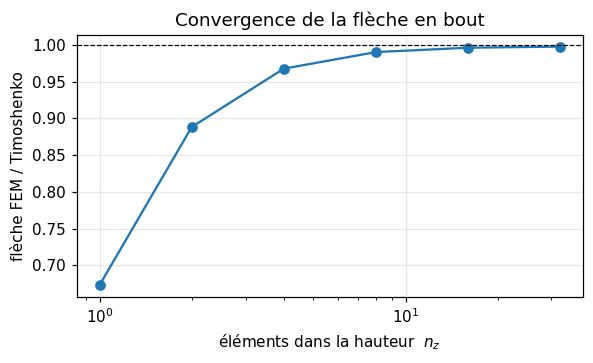

In [9]:
def resoudre_console(s_e, nx, nz, L, H, t, C, F):
    # Console encastrée à gauche, force F vers le bas répartie sur le bord droit. Renvoie u, f, ed, Ke0, noeuds.
    hx, hz = L / nx, H / nz
    Ke0 = Ke0_q1(C, hx, hz, t)
    K, ed = assembler_K(s_e, Ke0, nx, nz)
    noeuds = np.arange((nx + 1) * (nz + 1)).reshape(nx + 1, nz + 1)          # numéro de nœud [i, k]
    bloques = np.r_[2 * noeuds[0, :], 2 * noeuds[0, :] + 1]                  # bord gauche : ux = uz = 0
    poids = np.full(nz + 1, 1.0 / nz); poids[[0, -1]] = 0.5 / nz             # répartition trapézoïdale (somme = 1)
    f = np.zeros(K.shape[0]); f[2 * noeuds[-1, :] + 1] = -F * poids          # composante z du bord droit
    return resoudre(K, f, bloques), f, ed, Ke0, noeuds

E, nu, t = 2.0e9, 0.3, 0.010
C_pl = E / (1 - nu ** 2) * np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu) / 2]])
L, H, F = 0.100, 0.010, 10.0
I, A, Gm = t * H ** 3 / 12, t * H, E / (2 * (1 + nu))
delta_timo = F * L ** 3 / (3 * E * I) + F * L / ((5 / 6) * Gm * A)

nzs = [1, 2, 4, 8, 16, 32]
ratio = []
print(f"flèche de Timoshenko : {delta_timo * 1e3:.4f} mm\n")
print(f"{'nz':>4s} {'nx':>5s} {'inconnues':>10s} {'flèche FEM [mm]':>16s} {'FEM / Timoshenko':>17s}")
for nz in nzs:
    nx = 10 * nz
    u, f, ed, Ke0, noeuds = resoudre_console(np.ones(nx * nz), nx, nz, L, H, t, C_pl, F)
    delta = -u[2 * noeuds[-1, :] + 1].mean()                                  # flèche moyenne du bord libre
    ratio.append(delta / delta_timo)
    print(f"{nz:4d} {nx:5d} {len(u):10d} {delta * 1e3:16.4f} {ratio[-1]:17.4f}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.semilogx(nzs, ratio, "o-"); ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("éléments dans la hauteur  $n_z$"); ax.set_ylabel("flèche FEM / Timoshenko")
ax.set_title("Convergence de la flèche en bout"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Lecture.** Avec **un seul élément** dans la hauteur, la flèche est sous-estimée de 33 % (la poutre numérique est trop raide) ; avec 4 éléments l'écart tombe à 3 %, avec 8 à 1 %, puis la flèche semble se stabiliser vers 99,8 % de la valeur de Timoshenko. L'écart résiduel vient des hypothèses de la théorie des poutres (encastrement idéal, répartition du cisaillement), pas du code.

Ce phénomène de **raideur excessive en flexion avec peu d'éléments** (le *verrouillage en cisaillement*, *shear locking*) est un défaut connu de l'élément Q1. Conséquence pratique pour le projet : **un membre de la structure doit couvrir plusieurs éléments dans son épaisseur**. C'est l'un des arguments en faveur de la règle « rayon de filtre $R\ge3h$ » ([FORMALISM §6](../../FORMALISM.md)) : le filtre évite des barres de l'ordre d'un ou deux éléments d'épaisseur, là où le Q1 est peu fiable.

### Contraintes dans la poutre

À partir des déplacements nodaux, la déformation au centre de chaque élément est $\boldsymbol\varepsilon=\mathbf B(0,0)\,\mathbf u_e$ et la contrainte $\boldsymbol\sigma=\mathbf C\boldsymbol\varepsilon$. La théorie des poutres prédit $\sigma_{xx}(x,z)=\dfrac{F}{t}\,\dfrac{(L-x)\,(z-H/2)}{H^3/12}$ : **linéaire dans la hauteur**, nulle sur la **fibre neutre** ($z=H/2$), et maximale en peau.

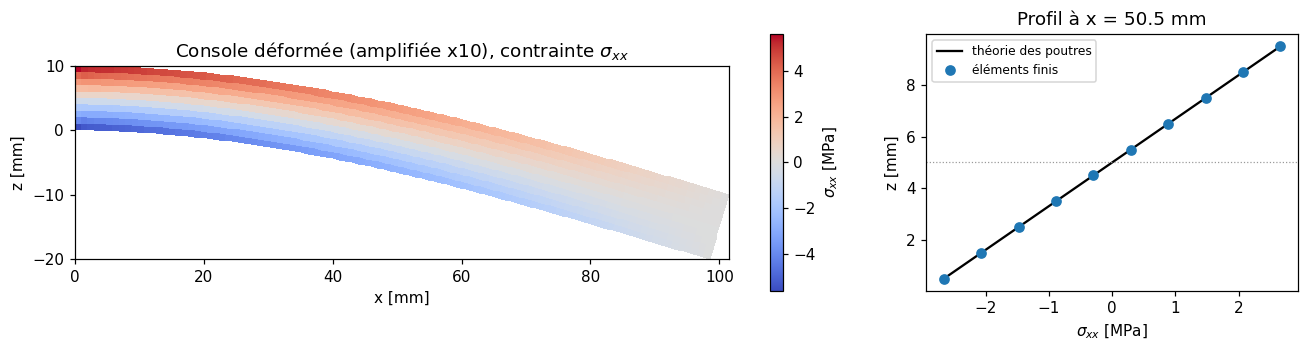

écart max du profil (relatif au max de la théorie) : 0.5 %
compliance f.u = 2.001578e-02 J ;  2 x énergie = 2.001578e-02 J


In [10]:
nz = 10; nx = 100
u, f, ed, Ke0, noeuds = resoudre_console(np.ones(nx * nz), nx, nz, L, H, t, C_pl, F)
hx, hz = L / nx, H / nz

# contraintes au centre de chaque élément : sigma = C B(0,0) u_e   (calcul groupé sur tous les éléments)
B0 = B_q1(0.0, 0.0, hx, hz)
sigma = (u[ed] @ B0.T) @ C_pl.T                       # (Ne, 3) : sxx, szz, sxz
sxx = sigma[:, 0].reshape(nx, nz) / 1e6               # MPa, tableau [i, k]

# profil dans la hauteur, à mi-longueur
i_mid = nx // 2
x_mid = (i_mid + 0.5) * hx
z_c = (np.arange(nz) + 0.5) * hz
sxx_poutre = (F / t) * (L - x_mid) * (z_c - H / 2) / (H ** 3 / 12) / 1e6
err = np.abs(sxx[i_mid, :] - sxx_poutre).max() / np.abs(sxx_poutre).max()

# maillage déformé (amplifié) coloré par sigma_xx
X = np.arange(nx + 1)[:, None] * hx * np.ones(nz + 1) * 1e3
Z = np.ones(nx + 1)[:, None] * np.arange(nz + 1) * hz * 1e3
amp = 10.0
Xd = X + amp * u[2 * noeuds] * 1e3
Zd = Z + amp * u[2 * noeuds + 1] * 1e3

fig, axs = plt.subplots(1, 2, figsize=(12, 3.3), gridspec_kw=dict(width_ratios=[2.2, 1]))
m = axs[0].pcolormesh(Xd, Zd, sxx, cmap="coolwarm", vmin=-np.abs(sxx).max(), vmax=np.abs(sxx).max(), shading="flat")
plt.colorbar(m, ax=axs[0], label=r"$\sigma_{xx}$ [MPa]")
axs[0].set_aspect("equal"); axs[0].set_xlabel("x [mm]"); axs[0].set_ylabel("z [mm]")
axs[0].set_title(f"Console déformée (amplifiée x{amp:.0f}), contrainte $\\sigma_{{xx}}$")
axs[1].plot(sxx_poutre, z_c * 1e3, "k-", label="théorie des poutres")
axs[1].plot(sxx[i_mid, :], z_c * 1e3, "o", label="éléments finis")
axs[1].axhline(H / 2 * 1e3, color="0.6", lw=0.8, ls=":")
axs[1].set_xlabel(r"$\sigma_{xx}$ [MPa]"); axs[1].set_ylabel("z [mm]"); axs[1].legend(fontsize=8)
axs[1].set_title(f"Profil à x = {x_mid * 1e3:.1f} mm")
plt.tight_layout(); plt.show()
print(f"écart max du profil (relatif au max de la théorie) : {100 * err:.1f} %")

# identité du notebook 2, valable en 2D : compliance = f . u = 2 x énergie de déformation
energie = 0.5 * np.einsum("ei,ij,ej->e", u[ed], Ke0, u[ed])
print(f"compliance f.u = {f @ u:.6e} J ;  2 x énergie = {2 * energie.sum():.6e} J")

Le champ de contrainte est bien celui d'une poutre : traction en haut (rouge), compression en bas (bleu), valeur nulle sur la **fibre neutre**. Et l'égalité *compliance = 2 × énergie de déformation* du notebook 2 reste vraie en 2D.

> **Observation à retenir pour la suite.** La matière proche de la fibre neutre est peu sollicitée ($\sigma_{xx}\approx0$) ; celle en peau l'est beaucoup. L'optimisation topologique en tirera la même conclusion : creuser le cœur d'une poutre en flexion coûte peu de rigidité, d'où le profil en I. Vérifions-le directement.

## 6. Le même maillage, une rigidité par élément : l'effet d'un trou

La grille ne change jamais ; on modifie seulement le coefficient $s_e$ de chaque élément. Un **trou** est simplement une zone où $s_e\approx0$. Plus exactement on prend $s_e=\varepsilon_s+(1-\varepsilon_s)\rho_e$ avec $\varepsilon_s=10^{-9}$ (rigidité du vide non strictement nulle, pour que $\mathbf K$ reste inversible). C'est le futur SIMP de la leçon 8, avec $p=1$.

Expérience : une console de 80 × 30 mm (maillage 80 × 30), chargée en bout par 100 N. On perce un **même trou** (rayon 7 mm, ≈ 6,5 % de la matière), d'abord au centre (sur la fibre neutre), puis décalé vers la peau du haut. On compare la compliance et on regarde où l'énergie de déformation est stockée.

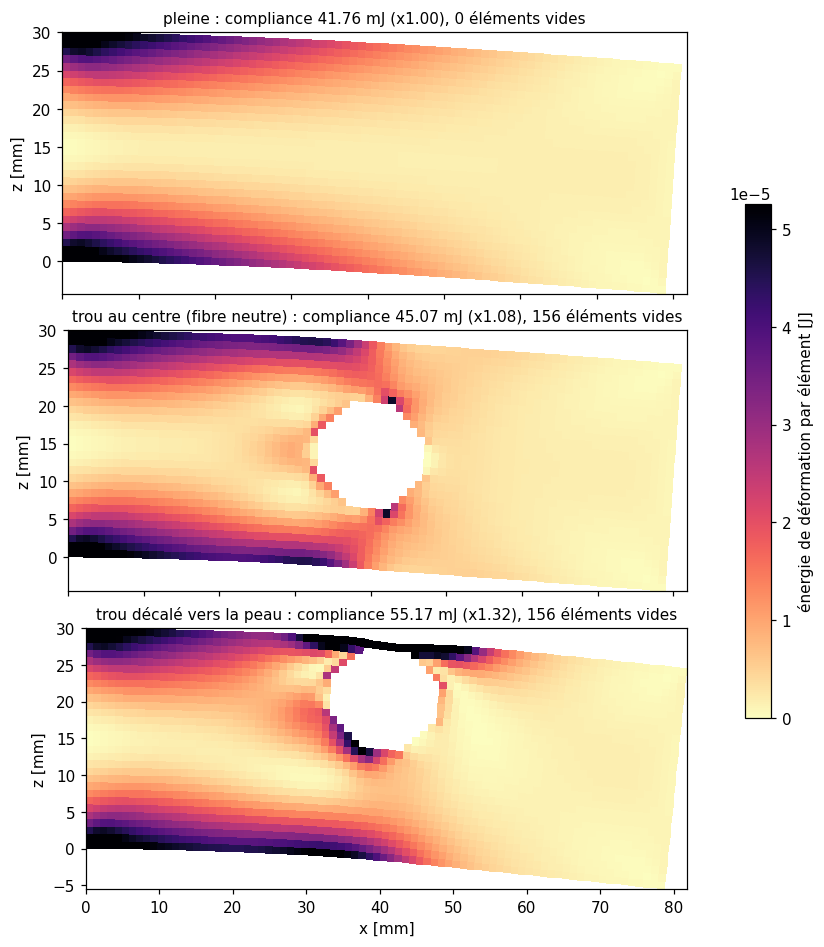

écart relatif sur C entre eps_s = 1e-9 et 1e-6 : 3.9e-07


In [11]:
L, H, F = 0.080, 0.030, 100.0
nx, nz = 80, 30
hx, hz = L / nx, H / nz
xc = (np.arange(nx) + 0.5) * hx
zc = (np.arange(nz) + 0.5) * hz
Xc, Zc = np.meshgrid(xc, zc, indexing="ij")
eps_s = 1e-9

def console_trouee(z_trou, r=0.007):
    rho = np.ones((nx, nz))
    if z_trou is not None:
        rho[(Xc - L / 2) ** 2 + (Zc - z_trou) ** 2 < r ** 2] = 0.0
    s_e = eps_s + (1 - eps_s) * rho.ravel()
    u, f, ed, Ke0, noeuds = resoudre_console(s_e, nx, nz, L, H, t, C_pl, F)
    energie_e = 0.5 * s_e * np.einsum("ei,ij,ej->e", u[ed], Ke0, u[ed])        # énergie de chaque élément
    return rho, u, f @ u, energie_e.reshape(nx, nz), noeuds

cas = [("pleine", None), ("trou au centre (fibre neutre)", 0.015), ("trou décalé vers la peau", 0.022)]
resultats = [console_trouee(z) for _, z in cas]
C_pleine = resultats[0][2]
vmax = np.percentile(resultats[0][3], 99)                    # même échelle de couleur pour les trois panneaux

X = np.arange(nx + 1)[:, None] * hx * np.ones(nz + 1) * 1e3
Z = np.ones(nx + 1)[:, None] * np.arange(nz + 1) * hz * 1e3
fig, axs = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True, layout="constrained")
for ax, (nom, _), (rho, u, C, En, noeuds) in zip(axs, cas, resultats):
    amp = 10.0
    Xd, Zd = X + amp * u[2 * noeuds] * 1e3, Z + amp * u[2 * noeuds + 1] * 1e3
    m = ax.pcolormesh(Xd, Zd, np.ma.masked_where(rho == 0, En), cmap="magma_r", vmin=0, vmax=vmax, shading="flat")
    ax.set_aspect("equal"); ax.set_ylabel("z [mm]")
    ax.set_title(f"{nom} : compliance {C * 1e3:.2f} mJ (x{C / C_pleine:.2f}), {int((rho == 0).sum())} éléments vides", fontsize=10)
axs[-1].set_xlabel("x [mm]")
fig.colorbar(m, ax=list(axs), shrink=0.6, label="énergie de déformation par élément [J]")
plt.show()

# le résultat dépend-il de eps_s ? (il ne doit pas)
_, _, C_a, _, _ = console_trouee(0.015)
eps_s = 1e-6
_, _, C_b, _, _ = console_trouee(0.015)
eps_s = 1e-9
print(f"écart relatif sur C entre eps_s = 1e-9 et 1e-6 : {abs(C_a - C_b) / C_a:.1e}")

**Résultat.** Pour **la même quantité de matière retirée** (156 éléments), le trou au centre augmente la compliance de **8 %**, le trou près de la peau de **32 %**, soit quatre fois plus. Les panneaux montrent pourquoi : l'énergie de déformation (en sombre) se concentre en peau et à l'encastrement ; autour du trou central elle est faible, alors que le trou décalé coupe une zone très sollicitée et force les efforts à le contourner.

C'est l'intuition de l'optimisation topologique : **une pièce optimale retire la matière là où l'énergie est faible et la garde là où elle est forte**. L'algorithme du projet fera cela automatiquement, élément par élément, en s'appuyant sur le gradient de la compliance (leçon 7), sans qu'on lui dise où percer.

## À retenir

| Idée | Dans le projet |
|---|---|
| $\boldsymbol\varepsilon=(\varepsilon_{xx},\varepsilon_{zz},\gamma_{xz})$ ; un mouvement rigide ne déforme pas | ordre de Voigt, 3 modes rigides en 2D (6 en 3D) |
| $\boldsymbol\sigma=\mathbf C\boldsymbol\varepsilon$ ; $\mathbf C=\mathbf S^{-1}$, $\mathbf S$ vérifiée définie positive (Cholesky) | `Orthotropic` : isotrope, isotrope transverse, orthotrope ; vérification d'admissibilité |
| Contraintes planes (extraire puis inverser) vs déformations planes (inverser puis extraire) | `plane: stress` par défaut |
| $\mathbf K_e^0=t\sum_g w_g\det J\,\mathbf B_g^\top\mathbf C_0\mathbf B_g$ : **une seule** matrice $8\times8$ (24×24 en 3D) pour toute la grille | `ke0(...)`, validée par les 5 tests du §3 (dont top88) |
| $\mathbf K=\sum_e s_e\,\mathbf A_e^\top\mathbf K_e^0\mathbf A_e$ : gather → produit → scatter-add | opérateur de rigidité |
| $\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P)$ | conditions aux limites |
| Compliance $=\mathbf f^\top\mathbf u=2\times$énergie, même en 2D | objectif mécanique |
| Q1 : verrouillage si moins de ~4 éléments dans l'épaisseur | rayon de filtre $R\ge3h$ |
| Le trou = un $s_e\approx0$ ; son coût dépend de l'endroit | principe de l'optimisation topologique |

**Pour expérimenter.** (i) Au §5, remplacez `C_pl` par la matrice orthotrope `C_ti` du §2 : la flèche est multipliée par environ $E/E_p\approx0{,}83$. Pourquoi la flexion le long de $x$ ne « voit »-elle presque que $E_p$ ? Que se passerait-il si la poutre était imprimée debout, couches empilées le long de son axe ? (ii) Au §6, essayez un trou par-dessus l'encastrement (x = 5 mm) : la compliance augmente-t-elle plus ou moins qu'au centre ? (iii) Remplacez la console par un appui simple (ddl $u_z$ bloqué aux deux extrémités) et chargez au milieu.

*Suite : leçon 4 (passer en 3D), puis leçon 6 (opérateur sans matrice : même résultat, sans jamais construire $\mathbf K$). Voir le [plan des leçons](README.md).*